# 03 – Nội dung 4: Xây dựng hệ hỗ trợ ra quyết định (DSS)

Công việc 4.1 (tiêu chí & bộ luật), 4.2 (module dự đoán), 4.3 (5 kịch bản CSKH), 4.4 (cảnh báo sớm).

> **Quyền riêng tư:** `customer_id` là mã giả danh (`KH_` + HMAC, không suy ngược được nếu không có khóa); dữ liệu không còn số điện thoại hay họ tên. Notebook chỉ hiển thị số liệu tổng hợp và mã đã che.

> **Tái lập:** chạy `python omni_dss/train_pipeline.py` trước (sinh mô hình và các file kết quả trong `omni_dss/saved_models/`).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # bảng màu đã kiểm định CVD
LEVEL_COLOR = {"CRITICAL": "#d03b3b", "HIGH": "#eb6834", "MEDIUM": "#eda100", "LOW": "#1baf7a"}
from omni_dss.ml import feature_engineering as fe
from omni_dss.ml.config import SAVED_MODELS_DIR
SM = Path(SAVED_MODELS_DIR)
def load(name): return json.load(open(SM / name, encoding="utf-8"))

## 0. Luồng xử lý của hệ DSS

```
Đơn hàng (point-in-time) ─► Đặc trưng hành vi ─► Mô hình churn (XGBoost) ─► Percentile rủi ro (0–100)
                                       └──────► K-Means RFM ─► Phân khúc ──┐            │
                                                                          ▼            ▼
                                                            Bộ luật DSS (10 luật, CV 4.1)
                                                                          │
                                       ┌──────────────────────────────────┴───────────────┐
                                       ▼                                                  ▼
                       Mức cảnh báo + kịch bản CSKH (CV 4.3)          Danh sách cảnh báo sớm kèm lý do SHAP (CV 4.4)
```

Mã nguồn: `omni_dss/ml/predict.py` (CV 4.2), `omni_dss/ml/risk_rank.py` (thang rủi ro), `omni_dss/ml/dss.py` (luật, kịch bản, cảnh báo).

## 1. CV 4.1 — Tiêu chí và bộ luật

### 1.1. Tiêu chí rủi ro: vì sao dùng **thứ hạng** thay cho xác suất
Mô hình được huấn luyện có cân bằng lớp (tỷ lệ churn ~96%), nên xác suất đầu ra bị kéo lệch. Bảng dưới so sánh xác suất dự đoán trung bình với tỷ lệ churn thực tế theo từng thập phân vị điểm trên tập kiểm tra out-of-time.

In [2]:
cal = load("model_evaluation.json")["calibration"]
t = pd.DataFrame(cal["bins"]).set_index("decile")
print(f"Xác suất dự đoán TB {cal['mean_predicted']:.3f} so với tỷ lệ churn thực tế {cal['actual_rate']:.3f}; ECE = {cal['expected_calibration_error']:.3f}")
t.style.format({"mean_predicted": "{:.3f}", "actual_rate": "{:.3f}"})

Xác suất dự đoán TB 0.549 so với tỷ lệ churn thực tế 0.962; ECE = 0.414


,customers,mean_predicted,actual_rate
decile,,,
1,273,0.327,0.930
2,272,0.349,0.963
3,272,0.418,0.930
4,273,0.507,0.956
5,272,0.564,0.967
6,272,0.597,0.974
7,273,0.624,0.974
8,272,0.654,0.978
9,272,0.684,0.971


Xác suất tuyệt đối lệch xa thực tế (ví dụ dự đoán ~0,33 nhưng thực tế ~0,93), nên ngưỡng cố định kiểu "xác suất > 70%" không có nghĩa. Mô hình chỉ đáng tin ở khả năng **xếp hạng**. Vì vậy tiêu chí rủi ro là **percentile**: vị trí của khách so với phân bố điểm trên tập tham chiếu (2.724 khách kiểm tra).

| Bậc | Percentile | Ý nghĩa |
|---|---|---|
| Cao | > 90 | 10% khách có điểm rủi ro cao nhất |
| Trung bình | 60–90 | 30% kế tiếp |
| Thấp | < 60 | 60% còn lại |
| Cơ hội (khách tiềm năng) | ≤ 20, phân khúc VIP/Tiềm năng | 20% rủi ro thấp nhất |

Căn cứ chọn ngưỡng (đánh đổi quy mô – độ chính xác) nằm ở notebook 04, mục 2.4.

### 1.2. Bộ luật (10 luật)
Mức cảnh báo cuối cùng = mức **cao nhất** trong các luật khớp; mỗi luật gắn với một kịch bản CSKH.

In [3]:
from omni_dss.ml.dss import describe_rules, describe_strategies, evaluate_customer, apply_dss, early_warning_list, CANONICAL_SEGMENTS, LEVEL_PRIORITY, STRATEGIES, mask_customer_id
describe_rules()

,Luật,Mức,Phân khúc,Percentile rủi ro,Kịch bản,Cảnh báo,Khuyến nghị
0,R01_VIP_CRITICAL,CRITICAL,VIP,"(90, 100]",KB1 – Cứu vãn khẩn cấp,Khách hàng VIP có nguy cơ rời bỏ rất cao,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
1,R02_HIGH_CHURN,HIGH,Mọi phân khúc trừ VIP,"(90, 100]",KB1 – Cứu vãn khẩn cấp,Nguy cơ rời bỏ cao,Gửi voucher giảm giá 15% và CSKH liên hệ trực tiếp
2,R03_AT_RISK_MEDIUM_CHURN,HIGH,Rủi ro,"[60, 90]",KB2 – Win-back nhóm Rủi ro,Khách hàng nhóm Rủi ro đang có dấu hiệu rời bỏ,Kích hoạt chiến dịch win-back: mã giảm giá 15% kèm freeship cho đơn kế tiếp
3,R04_AT_RISK_FLOOR,MEDIUM,Rủi ro,"[0, 60)",KB2 – Win-back nhóm Rủi ro,Khách hàng nhóm Rủi ro (giá trị/tần suất thấp) cần được theo dõi,Gửi khảo sát trải nghiệm & mã giảm giá 10% để kích hoạt đơn thành công đầu tiên
4,R05_VIP_DECLINING,MEDIUM,VIP,"[20, 90]",KB3 – Giữ chân khách giá trị đang giảm tương tác,Khách hàng VIP đang giảm tần suất mua sắm,Gửi quà tặng cá nhân hóa & gán chuyên viên hỗ trợ riêng
5,R06_POTENTIAL_DECLINING,MEDIUM,Tiềm năng,"[60, 90]",KB3 – Giữ chân khách giá trị đang giảm tương tác,Khách hàng tiềm năng có dấu hiệu sụt giảm tương tác,Gửi email nhắc giỏ hàng kèm ưu đãi freeship
6,R07_NEEDS_ATTENTION,MEDIUM,Cần chăm sóc,"[0, 90]",KB4 – Kích hoạt lại nhu cầu,Cần kích hoạt lại nhu cầu mua sắm,Khảo sát trải nghiệm dịch vụ & gửi mã giảm giá 10%
7,R08_UNKNOWN_MEDIUM_CHURN,MEDIUM,Không xác định,"[60, 90]",KB4 – Kích hoạt lại nhu cầu,Nguy cơ rời bỏ trung bình (chưa xác định phân khúc),Chạy phân cụm RFM để xác định phân khúc và theo dõi tương tác trong 14 ngày
8,R09_VIP_LOYAL,LOW,VIP,"[0, 20)",KB5 – Tri ân & bán thêm,—,Mời tham gia chương trình tri ân đặc quyền
9,R10_POTENTIAL_GROWTH,LOW,Tiềm năng,"[0, 60)",KB5 – Tri ân & bán thêm,—,Gợi ý sản phẩm cross-sell/up-sell và tích điểm thưởng kép


### 1.3. Ma trận quyết định: phân khúc × percentile rủi ro → mức cảnh báo

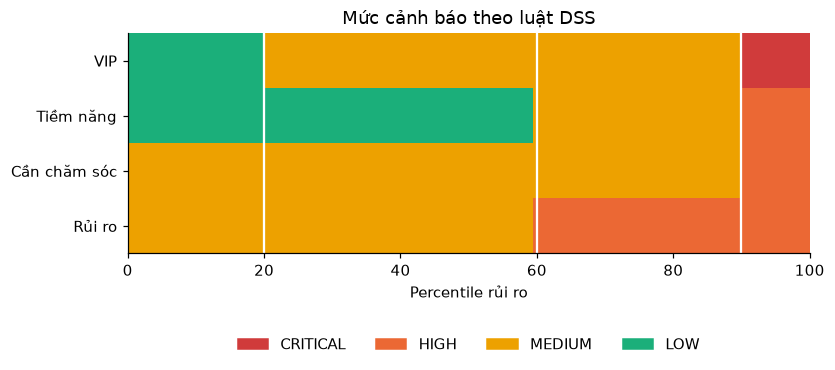

In [4]:
grid = np.arange(0, 101, 1.0)
lv = {seg: [LEVEL_PRIORITY[evaluate_customer(seg, p)["alert_level"]] for p in grid] for seg in CANONICAL_SEGMENTS}
from matplotlib.colors import ListedColormap
cmap = ListedColormap([LEVEL_COLOR[k] for k in ("LOW", "MEDIUM", "HIGH", "CRITICAL")])
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.imshow(np.array(list(lv.values())), aspect="auto", cmap=cmap, vmin=1, vmax=4, extent=[0, 100, len(lv) - 0.5, -0.5])
ax.set_yticks(range(len(lv))); ax.set_yticklabels(lv.keys()); ax.set_xlabel("Percentile rủi ro"); ax.grid(False)
for x in (20, 60, 90): ax.axvline(x, color="white", lw=1.5)
handles = [plt.Rectangle((0, 0), 1, 1, color=LEVEL_COLOR[k]) for k in ("CRITICAL", "HIGH", "MEDIUM", "LOW")]
ax.legend(handles, ["CRITICAL", "HIGH", "MEDIUM", "LOW"], ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.32), frameon=False)
ax.set_title("Mức cảnh báo theo luật DSS");

## 2. CV 4.2 — Module dự đoán hành vi khách hàng
`Predictor` nạp mô hình đã huấn luyện và chấm điểm mọi khách **tại một mốc thời gian bất kỳ** (chỉ dùng thông tin đã biết tại mốc đó). Ở đây chấm tại **ngày cuối của dữ liệu**, đúng cách hệ thống được dùng trong vận hành: "hôm nay cần chăm sóc ai?". Khách đủ điều kiện: có đơn trong 30 ngày gần nhất (cùng tiêu chí với đánh giá walk-forward).

In [5]:
from omni_dss.ml.predict import Predictor
orders = fe.load_orders()
as_of = orders["order_time"].max() + pd.Timedelta(seconds=1)
pred = Predictor.load()
agg = fe.build_customer_aggregates(orders, as_of)
active = agg[agg["recency_days"] <= 30]
scored = active.join(pred.score_aggregates(active, top_k=3, explain_limit=500))
print(f"Mốc as-of: {as_of:%Y-%m-%d %H:%M} | khách có đơn trước mốc: {len(agg):,} | khách active 30 ngày: {len(scored):,} | mô hình: {pred.model_name}")
scored[["churn_prob", "repurchase_prob", "risk_percentile"]].describe().T.round(3)

Mốc as-of: 2022-11-11 10:59 | khách có đơn trước mốc: 19,100 | khách active 30 ngày: 17,778 | mô hình: XGBoost


,count,mean,std,min,25%,50%,75%,max
churn_prob,17778.0,0.573,0.129,0.142,0.489,0.607,0.656,0.905
repurchase_prob,17778.0,0.427,0.129,0.095,0.344,0.393,0.511,0.858
risk_percentile,17778.0,54.735,26.867,0.000,31.570,58.660,75.400,100.000


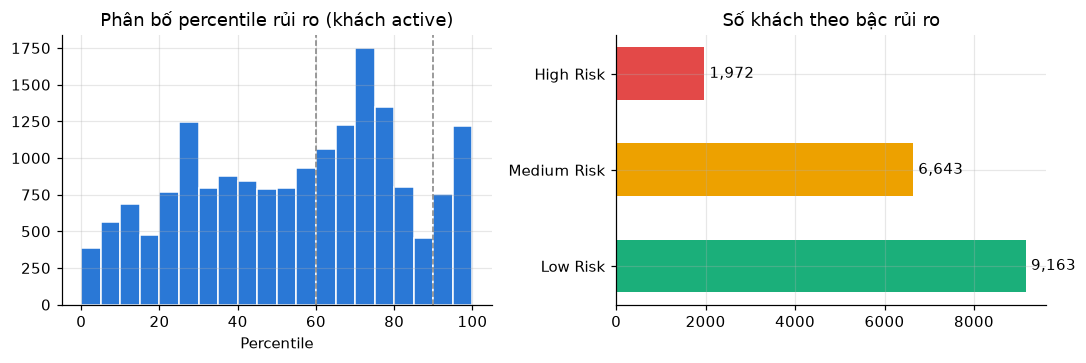

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(scored["risk_percentile"], bins=20, color=C[0], edgecolor="white")
for x in (60, 90): axes[0].axvline(x, color="gray", ls="--", lw=1)
axes[0].set_title("Phân bố percentile rủi ro (khách active)"); axes[0].set_xlabel("Percentile")
seg_lvl = scored["risk_level"].value_counts().reindex(["High Risk", "Medium Risk", "Low Risk"])
axes[1].barh(seg_lvl.index[::-1], seg_lvl.values[::-1], color=[C[2], C[3], C[7]], height=0.55)
for i, v in enumerate(seg_lvl.values[::-1]): axes[1].text(v, i, f" {v:,}", va="center")
axes[1].set_title("Số khách theo bậc rủi ro"); plt.tight_layout()

In [7]:
# Thang đo cố định theo tập tham chiếu: nếu khách hiện tại giống tập tham chiếu thì trung vị ~50, ~10% vượt 90
p_ = scored["risk_percentile"]
print(f"Trung vị percentile: {p_.median():.1f} | tỷ lệ > 90: {(p_ > 90).mean():.1%} | tỷ lệ ≤ 60: {(p_ <= 60).mean():.1%}")
print("-> Phân bố càng lệch khỏi (50; 10%; 60%) thì tập khách hiện tại càng khác tập tham chiếu (cần huấn luyện lại).")

Trung vị percentile: 58.7 | tỷ lệ > 90: 11.1% | tỷ lệ ≤ 60: 51.5%
-> Phân bố càng lệch khỏi (50; 10%; 60%) thì tập khách hiện tại càng khác tập tham chiếu (cần huấn luyện lại).


### 2.1. Ví dụ dự đoán một khách (kèm lý do SHAP)

In [8]:
ex = scored.sort_values("risk_percentile", ascending=False).iloc[0]
print("Khách:", mask_customer_id(ex.name), "| phân khúc:", ex["rfm_segment"], f"| percentile rủi ro {ex['risk_percentile']:.1f} | điểm mô hình {ex['churn_prob']:.3f}")
pd.DataFrame(ex["top_factors"])[["label", "value", "shap_value", "effect"]]

Khách: KH_WURXCMA5PC | phân khúc: Tiềm năng | percentile rủi ro 100.0 | điểm mô hình 0.869


,label,value,shap_value,effect
0,Kênh chính: TikTok Shop,1.0,0.83993,tăng rủi ro rời bỏ
1,Vùng: Miền Bắc,1.0,0.52773,tăng rủi ro rời bỏ
2,Tỷ lệ đơn đang xử lý,0.0,0.21407,tăng rủi ro rời bỏ


## 3. CV 4.3 — Năm kịch bản Marketing & CSKH cá nhân hóa
Mỗi luật trỏ tới đúng một kịch bản; kịch bản của khách = kịch bản của luật có mức cảnh báo cao nhất.

In [9]:
describe_strategies()

,Mã,Kịch bản,Mục tiêu,Hành động,Chỉ số đo hiệu quả,Luật kích hoạt
0,KB1,Cứu vãn khẩn cấp,Giữ lại khách thuộc nhóm rủi ro rời bỏ cao nhất trước khi mất hẳn,CSKH gọi điện/nhắn tin trong 24h; voucher 15–20%; VIP có chuyên viên riêng và quà tri ân,Tỷ lệ đặt đơn mới trong 14 ngày sau liên hệ so với nhóm không liên hệ,"R01_VIP_CRITICAL, R02_HIGH_CHURN"
1,KB2,Win-back nhóm Rủi ro,Kích hoạt đơn thành công đầu tiên cho khách có đơn hủy/hoàn hoặc giá trị thấp,Khảo sát trải nghiệm; mã giảm 10–15% kèm freeship cho đơn kế tiếp,Tỷ lệ khách có đơn thành công đầu tiên trong 30 ngày,"R03_AT_RISK_MEDIUM_CHURN, R04_AT_RISK_FLOOR"
2,KB3,Giữ chân khách giá trị đang giảm tương tác,Ngăn VIP/Tiềm năng trượt xuống nhóm rủi ro,"Quà tặng cá nhân hóa, nhắc giỏ hàng, ưu đãi freeship",Tỷ lệ mua lại và giá trị đơn trung bình của nhóm VIP/Tiềm năng,"R05_VIP_DECLINING, R06_POTENTIAL_DECLINING"
3,KB4,Kích hoạt lại nhu cầu,Đưa khách Cần chăm sóc / chưa rõ phân khúc quay lại mua,"Khảo sát dịch vụ, mã giảm 10%, theo dõi tương tác 14 ngày",Tỷ lệ mở/nhấp chiến dịch và tỷ lệ đặt đơn,"R07_NEEDS_ATTENTION, R08_UNKNOWN_MEDIUM_CHURN"
4,KB5,Tri ân & bán thêm,Khai thác khách giá trị có rủi ro thấp (cơ hội tăng doanh thu),"Chương trình tri ân đặc quyền, gợi ý cross-sell/up-sell, điểm thưởng kép","Doanh thu bán thêm, tỷ lệ mua lại của nhóm khách tiềm năng","R09_VIP_LOYAL, R10_POTENTIAL_GROWTH"


In [10]:
dss = apply_dss(scored)
names = {k: f"{k} – {s.name}" for k, s in STRATEGIES.items()}
tab = pd.crosstab(dss["rfm_segment"], dss["strategy"].map(names), margins=True, margins_name="Tổng")
tab

strategy,KB1 – Cứu vãn khẩn cấp,KB2 – Win-back nhóm Rủi ro,KB3 – Giữ chân khách giá trị đang giảm tương tác,KB4 – Kích hoạt lại nhu cầu,KB5 – Tri ân & bán thêm,Tổng
rfm_segment,,,,,,
Cần chăm sóc,851,0,0,4593,0,5444
Rủi ro,242,3346,0,0,0,3588
Tiềm năng,857,0,2511,0,4330,7698
VIP,22,0,816,0,210,1048
Tổng,1972,3346,3327,4593,4540,17778


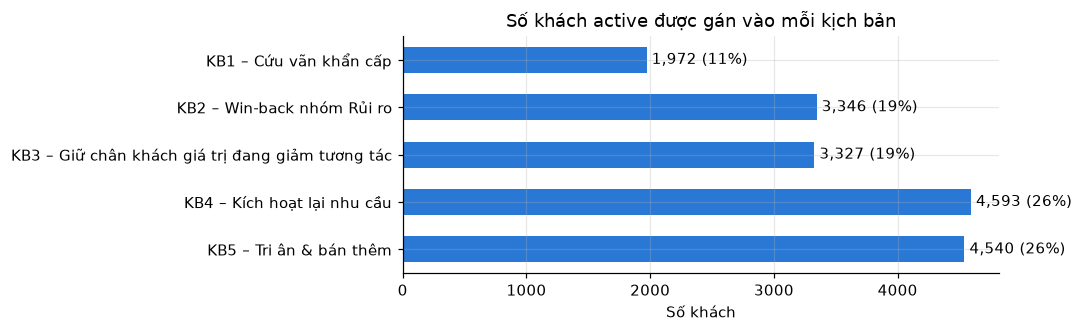

In [11]:
cnt = dss["strategy"].map(names).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(cnt.index[::-1], cnt.values[::-1], color=C[0], height=0.55)
for i, v in enumerate(cnt.values[::-1]): ax.text(v, i, f" {v:,} ({v / len(dss):.0%})", va="center")
ax.set_title("Số khách active được gán vào mỗi kịch bản"); ax.set_xlabel("Số khách");

## 4. CV 4.4 — Cơ chế cảnh báo sớm
Hai loại cảnh báo:
- **Cảnh báo rủi ro** (CRITICAL/HIGH): khách cần giữ chân, sắp theo mức rồi theo percentile.
- **Cảnh báo cơ hội**: VIP/Tiềm năng thuộc 20% rủi ro thấp nhất, phù hợp tri ân và bán thêm.

Mỗi cảnh báo kèm lý do (SHAP) và hành động khuyến nghị.

In [12]:
levels = dss["alert_level"].value_counts().reindex(["CRITICAL", "HIGH", "MEDIUM", "LOW"]).fillna(0).astype(int)
print("Phân bố mức cảnh báo:", levels.to_dict(), "| cảnh báo cơ hội:", int(dss["is_opportunity"].sum()))
ew = early_warning_list(dss)
def reasons(f): return "; ".join(x["label"] for x in f[:2]) if isinstance(f, list) and f else "—"
show = ew.head(15).assign(ma_khach=lambda d: [mask_customer_id(i) for i in d.index], ly_do=lambda d: d["top_factors"].map(reasons))
show[["ma_khach", "rfm_segment", "risk_percentile", "alert_level", "strategy", "ly_do", "recommendation"]]

Phân bố mức cảnh báo: {'CRITICAL': 22, 'HIGH': 2573, 'MEDIUM': 10643, 'LOW': 4540} | cảnh báo cơ hội: 409


,ma_khach,rfm_segment,risk_percentile,alert_level,strategy,ly_do,recommendation
customer_id,,,,,,,
KH_547UOPBZAS,KH_547UOPBZAS,VIP,96.18,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_XE3ZWBOMVU,KH_XE3ZWBOMVU,VIP,95.89,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_YOJT4NWCXD,KH_YOJT4NWCXD,VIP,95.63,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_KXL3NNUNFI,KH_KXL3NNUNFI,VIP,95.41,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_ZCOLR5MLP6,KH_ZCOLR5MLP6,VIP,95.08,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_N6KO5J32DJ,KH_N6KO5J32DJ,VIP,94.97,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_NPVS57A7VZ,KH_NPVS57A7VZ,VIP,94.82,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_VWBE473FTW,KH_VWBE473FTW,VIP,94.68,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"
KH_AGY7CSUJWY,KH_AGY7CSUJWY,VIP,94.53,CRITICAL,KB1,—,"Chuyên viên VIP liên hệ trong 24h, tặng voucher 20% và quà tri ân cá nhân hóa"


In [13]:
by = (dss.groupby(["region", "alert_level"]).size().unstack(fill_value=0)
      .reindex(columns=["CRITICAL", "HIGH", "MEDIUM", "LOW"], fill_value=0))
by.assign(**{"% cảnh báo cao": lambda d: (d["CRITICAL"] + d["HIGH"]) / d.sum(axis=1)}).style.format({"% cảnh báo cao": "{:.1%}"})

alert_level,CRITICAL,HIGH,MEDIUM,LOW,% cảnh báo cao
region,,,,,
Chưa xác định,0,0,1,0,0.0%
Miền Bắc,17,1600,586,36,72.2%
Miền Nam,5,815,8350,3755,6.3%
Miền Trung,0,158,1706,749,6.0%


In [14]:
opp = dss[dss["is_opportunity"]].sort_values("risk_percentile")
print(f"Cảnh báo cơ hội: {len(opp):,} khách")
opp.head(10).assign(ma_khach=lambda d: [mask_customer_id(i) for i in d.index])[["ma_khach", "rfm_segment", "risk_percentile", "completed_orders", "monetary", "recommendation"]]

Cảnh báo cơ hội: 409 khách


,ma_khach,rfm_segment,risk_percentile,completed_orders,monetary,recommendation
customer_id,,,,,,
KH_WEOKKTPIBW,KH_WEOKKTPIBW,Tiềm năng,0.0,1,700000.0,Gợi ý sản phẩm cross-sell/up-sell và tích điểm thưởng kép
KH_TYHNX7IRYK,KH_TYHNX7IRYK,Tiềm năng,0.0,1,900000.0,Gợi ý sản phẩm cross-sell/up-sell và tích điểm thưởng kép
KH_53RCSV75X6,KH_53RCSV75X6,VIP,0.0,2,1670000.0,Mời tham gia chương trình tri ân đặc quyền
KH_HRVQSUV7WO,KH_HRVQSUV7WO,Tiềm năng,0.0,1,1600000.0,Gợi ý sản phẩm cross-sell/up-sell và tích điểm thưởng kép
KH_DIMDCBWUMU,KH_DIMDCBWUMU,VIP,0.0,3,3151000.0,Mời tham gia chương trình tri ân đặc quyền
KH_ZAHYELM2VL,KH_ZAHYELM2VL,Tiềm năng,0.0,1,670000.0,Gợi ý sản phẩm cross-sell/up-sell và tích điểm thưởng kép
KH_CKF6EG6C2N,KH_CKF6EG6C2N,VIP,0.0,2,1070000.0,Mời tham gia chương trình tri ân đặc quyền
KH_BWXUHIM6CM,KH_BWXUHIM6CM,Tiềm năng,0.0,1,900000.0,Gợi ý sản phẩm cross-sell/up-sell và tích điểm thưởng kép
KH_AGCSBBCLW3,KH_AGCSBBCLW3,Tiềm năng,0.0,1,824000.0,Gợi ý sản phẩm cross-sell/up-sell và tích điểm thưởng kép


In [15]:
# Lưu danh sách cảnh báo (mã giả danh, không PII) cho bộ phận CSKH — file bị .gitignore, không commit
cols = ["rfm_segment", "risk_percentile", "risk_level", "alert_level", "strategy", "recommendation", "is_opportunity", "recency_days", "total_orders", "completed_orders", "monetary"]
out = dss[cols].assign(ly_do=dss["top_factors"].map(reasons)).sort_values("risk_percentile", ascending=False)
out.to_csv(SM / "early_warning_list.csv", encoding="utf-8")
summary = {"as_of": str(as_of), "active_customers": int(len(dss)), "alert_levels": levels.to_dict(),
           "opportunities": int(dss["is_opportunity"].sum()), "by_strategy": dss["strategy"].value_counts().to_dict()}
json.dump(summary, open(SM / "early_warning_summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
summary

{'as_of': '2022-11-11 10:59:45',
 'active_customers': 17778,
 'alert_levels': {'CRITICAL': 22, 'HIGH': 2573, 'MEDIUM': 10643, 'LOW': 4540},
 'opportunities': 409,
 'by_strategy': {'KB4': 4593,
  'KB5': 4540,
  'KB2': 3346,
  'KB3': 3327,
  'KB1': 1972}}

Hiệu quả của các cảnh báo này khi đối chiếu với hành vi thực tế được đánh giá ở **notebook 04**.